# Sugar Cosmetics – Instagram Performance Analytics
**Load → Clean → Transform → Explore**

The data is loaded straight from the Google Sheet (it must be shared as *"Anyone with the link"*). If you have no internet, put the CSV next to this notebook and set `USE_LOCAL_FILE = True`.

In [17]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
!{sys.executable} -m pip install openpyxl 

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

SHEET_ID = "1D22pa1iiJ-8uYirpZq-4GndO3id7XU-AE14Hybe0_qk"
SHEET_URL = f"https://docs.google.com/spreadsheets/d/{SHEET_ID}/export?format=csv"

USE_LOCAL_FILE = False
LOCAL_FILE = "sugar_cosmetics_instagram_data.csv"   # used only if USE_LOCAL_FILE = True

OUTPUT_DIR = Path("cleaned")
DAYFIRST = False   # dates in the sheet are YYYY-MM-DD, so leave False

REQUIRED = ["post_date", "post_type", "campaign_type", "hashtags", "audience_emotion",
            "engagement_source", "impressions", "reach", "likes", "comments",
            "shares", "saves", "profile_visits", "follows"]
COUNT_COLS = ["likes", "comments", "shares", "saves"]
NUMERIC = COUNT_COLS + ["reach", "impressions", "profile_visits", "follows"]
CATEGORY_COLS = ["post_type", "campaign_type", "audience_emotion", "engagement_source"]

POST_TYPE_MAP = {"image": "Image", "photo": "Image", "picture": "Image", "static": "Image",
                 "video": "Video", "vid": "Video",
                 "reel": "Reel", "reels": "Reel",
                 "story": "Story", "stories": "Story",
                 "carousel": "Carousel", "album": "Carousel", "carousel_album": "Carousel"}

log = []
def note(step, detail):
    log.append({"step": step, "detail": detail}); print(f"[{step}] {detail}")

## 1. Load data

In [18]:
raw = pd.read_csv(LOCAL_FILE) if USE_LOCAL_FILE else pd.read_csv(SHEET_URL)
print(raw.shape)
raw.head()

(50000, 14)


,Post Date,Post Type,Campaign Type,Hashtags,Audience Emotion,Engagement Source,Impressions,Reach,Likes,Comments,Shares,Saves,Profile Visits,Follows
0,2024-12-23,Story,Giveaway,"#SugarCosmetics, #MakeupGoals, #BoldLooks",Curious,Collab,16795,15665,3076,430,73,99,193,86
1,2024-06-01,Image,Tutorial,"#BoldLooks, #MakeupGoals, #VeganBeauty",Confident,Influencer,45131,29335,5285,308,396,502,294,146
2,2024-04-28,Reel,Festive Offer,#VeganBeauty,Confident,Collab,18568,13118,2032,233,73,140,204,44
3,2025-02-01,Reel,Product Launch,"#CrueltyFree, #VeganBeauty, #SugarCosmetics",Happy,Collab,1189,751,130,13,12,7,33,12
4,2024-08-04,Story,Tutorial,"#SugarCosmetics, #VeganBeauty",Curious,Organic,15502,9373,2234,300,99,47,180,35


## 2. Inspect raw data

In [19]:
raw.info()
print("\nMissing values per column:"); print(raw.isna().sum())
print("\nExact duplicate rows:", raw.duplicated().sum())
raw.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Post Date          50000 non-null  object
 1   Post Type          50000 non-null  object
 2   Campaign Type      50000 non-null  object
 3   Hashtags           50000 non-null  object
 4   Audience Emotion   50000 non-null  object
 5   Engagement Source  50000 non-null  object
 6   Impressions        50000 non-null  int64 
 7   Reach              50000 non-null  int64 
 8   Likes              50000 non-null  int64 
 9   Comments           50000 non-null  int64 
 10  Shares             50000 non-null  int64 
 11  Saves              50000 non-null  int64 
 12  Profile Visits     50000 non-null  int64 
 13  Follows            50000 non-null  int64 
dtypes: int64(8), object(6)
memory usage: 5.3+ MB

Missing values per column:
Post Date            0
Post Type            0
Campaign Type  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Post Date,50000,366,2024-08-13,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Post Type,50000,4,Reel,12599,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Campaign Type,50000,5,Tutorial,10186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hashtags,50000,85,#MakeupGoals,3403,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Audience Emotion,50000,5,Inspired,10137,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Engagement Source,50000,4,Collab,12633,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Impressions,50000.0,NaN,NaN,NaN,25520.915,14118.653466,1002.0,13243.0,25541.0,37758.25,49999.0
Reach,50000.0,NaN,NaN,NaN,19748.46576,11311.962456,616.0,10157.75,19393.5,28763.25,47329.0
Likes,50000.0,NaN,NaN,NaN,2954.56558,2144.918922,40.0,1256.0,2466.0,4255.0,11392.0
Comments,50000.0,NaN,NaN,NaN,369.18722,311.676485,2.0,135.0,282.0,516.0,2205.0


## 3. Helper functions

In [20]:
def to_number(value):
    """'1,234', '12.5K', '1.2M' -> numbers; bad values -> NaN."""
    if pd.isna(value): return np.nan
    if isinstance(value, (int, float, np.integer, np.floating)): return float(value)
    text = str(value).strip().lower().replace(",", "")
    if text in {"", "-", "n/a", "na", "nan", "null", "none"}: return np.nan
    mult = 1
    if text.endswith("k"): mult, text = 1_000, text[:-1]
    elif text.endswith("m"): mult, text = 1_000_000, text[:-1]
    try: return float(text) * mult
    except ValueError: return np.nan

def parse_dates(series, dayfirst=False):
    """ISO dates are always Y-M-D; other formats follow `dayfirst`."""
    text = series.astype(str).str.strip()
    iso = text.str.match(r"^\d{4}-\d{1,2}-\d{1,2}")
    out = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")
    out[iso] = pd.to_datetime(text[iso], errors="coerce", format="mixed")
    out[~iso] = pd.to_datetime(text[~iso], errors="coerce", format="mixed", dayfirst=dayfirst)
    return out

def parse_tags(value):
    """'#A, #B, #a' -> ['#a', '#b'] (lower-case, no duplicates)."""
    if pd.isna(value) or not str(value).strip(): return []
    text = str(value).lower()
    tags = re.findall(r"#\w+", text)
    if not tags:
        tags = ["#" + t for t in re.split(r"[,\s;|]+", text) if t]
    return list(dict.fromkeys(tags))

## 4. Cleaning

### 4.1 Standardise column names

In [21]:
df = raw.copy()
df.columns = (df.columns.astype(str).str.strip().str.lower()
              .str.replace(r"[^\w]+", "_", regex=True).str.strip("_"))
missing = [c for c in REQUIRED if c not in df.columns]
assert not missing, f"Missing required columns: {missing}"
df = df[REQUIRED]          # also drops the empty extra columns at the end of the sheet
note("Columns", f"names standardised to lower_snake_case; kept {len(REQUIRED)} columns")
list(df.columns)

[Columns] names standardised to lower_snake_case; kept 14 columns


['post_date',
 'post_type',
 'campaign_type',
 'hashtags',
 'audience_emotion',
 'engagement_source',
 'impressions',
 'reach',
 'likes',
 'comments',
 'shares',
 'saves',
 'profile_visits',
 'follows']

### 4.2 Trim text, blanks → null, remove empty rows & duplicates

In [22]:
for c in CATEGORY_COLS + ["hashtags"]:
    df[c] = df[c].astype("string").str.strip()
df = df.replace({"": pd.NA})

n = len(df)
df = df.dropna(how="all").drop_duplicates()
note("Duplicates", f"removed {n - len(df)} empty/duplicate rows ({n} -> {len(df)})")

[Duplicates] removed 0 empty/duplicate rows (50000 -> 50000)


### 4.3 Dates

In [23]:
n = len(df)
df["post_date"] = parse_dates(df["post_date"], DAYFIRST)
bad = int(df["post_date"].isna().sum())
df = df.dropna(subset=["post_date"])
future = df["post_date"] > pd.Timestamp.today().normalize()
df = df[~future]
note("Dates", f"dropped {bad} unparseable and {int(future.sum())} future-dated posts ({n} -> {len(df)})")

[Dates] dropped 0 unparseable and 0 future-dated posts (50000 -> 50000)


### 4.4 Numeric columns & missing values

In [24]:
for c in NUMERIC:
    df[c] = df[c].apply(to_number)
neg = int((df[NUMERIC] < 0).sum().sum())
df[NUMERIC] = df[NUMERIC].where(df[NUMERIC] >= 0)
note("Numbers", f"converted {len(NUMERIC)} metric columns to numeric; {neg} negative values set to null")

n = len(df)
fill_cols = COUNT_COLS + ["profile_visits", "follows"]
filled = int(df[fill_cols].isna().sum().sum())
df[fill_cols] = df[fill_cols].fillna(0)
df = df.dropna(subset=["reach", "impressions"])
df = df[(df["reach"] > 0) & (df["impressions"] > 0)]
df[NUMERIC] = df[NUMERIC].round().astype("int64")
note("Missing values", f"{filled} missing engagement/profile values filled with 0; "
     f"dropped {n - len(df)} rows with missing/zero reach or impressions")

[Numbers] converted 8 metric columns to numeric; 0 negative values set to null
[Missing values] 0 missing engagement/profile values filled with 0; dropped 0 rows with missing/zero reach or impressions


### 4.5 Standardise categories (post type, campaign, emotion, source)

In [25]:
key = df["post_type"].fillna("").str.lower().str.strip()
mapped = key.map(POST_TYPE_MAP)
unknown = mapped.isna()
mapped[unknown] = df.loc[unknown, "post_type"].fillna("Unknown").str.title()
df["post_type"] = mapped
for c in ["campaign_type", "audience_emotion", "engagement_source"]:
    df[c] = df[c].fillna("Unknown").str.strip().str.title()
note("Categories", "post_type: " + ", ".join(sorted(df["post_type"].unique())))
for c in CATEGORY_COLS:
    print(c, "->", df[c].value_counts().to_dict())

[Categories] post_type: Image, Reel, Story, Video
post_type -> {'Reel': 12599, 'Story': 12517, 'Video': 12485, 'Image': 12399}
campaign_type -> {'Tutorial': 10186, 'Giveaway': 9998, 'Festive Offer': 9990, 'Product Launch': 9923, 'Influencer Collab': 9903}
audience_emotion -> {'Inspired': 10137, 'Excited': 10061, 'Curious': 10027, 'Confident': 9891, 'Happy': 9884}
engagement_source -> {'Collab': 12633, 'Organic': 12508, 'Influencer': 12501, 'Paid': 12358}


### 4.6 Hashtags

In [26]:
tags = df["hashtags"].apply(parse_tags)
df["hashtags"] = tags.apply(" ".join)
df["hashtag_count"] = tags.apply(len)
note("Hashtags", "lower-cased, de-duplicated, counted per post")
df[["hashtags", "hashtag_count"]].head()

[Hashtags] lower-cased, de-duplicated, counted per post


,hashtags,hashtag_count
0,#sugarcosmetics #makeupgoals #boldlooks,3
1,#boldlooks #makeupgoals #veganbeauty,3
2,#veganbeauty,1
3,#crueltyfree #veganbeauty #sugarcosmetics,3
4,#sugarcosmetics #veganbeauty,2


## 5. Derived fields

In [27]:
df["interactions"] = df[COUNT_COLS].sum(axis=1)
df["engagement_rate_reach"] = (df["interactions"] / df["reach"] * 100).round(3)
df["engagement_rate_impr"]  = (df["interactions"] / df["impressions"] * 100).round(3)
df["profile_visit_rate"]    = (df["profile_visits"] / df["reach"] * 100).round(3)
df["follow_conversion"]     = (df["follows"] / df["profile_visits"].replace(0, np.nan) * 100).round(3)
df["post_date"] = df["post_date"].dt.normalize()
df["year"] = df["post_date"].dt.year
df["month"] = df["post_date"].dt.to_period("M").dt.to_timestamp()
df["month_label"] = df["month"].dt.strftime("%b %Y")
df["weekday"] = df["post_date"].dt.day_name()
df["weekday_num"] = df["post_date"].dt.dayofweek + 1   # Mon = 1
note("Derived fields", "interactions, engagement rates, profile visit rate, follow conversion, date parts")

[Derived fields] interactions, engagement rates, profile visit rate, follow conversion, date parts


## 6. Quality checks & outliers (flagged, not deleted)

In [28]:
flags = pd.Series("", index=df.index)
flags[df["reach"] > df["impressions"]] += "reach>impressions;"
flags[df["likes"] > df["reach"]] += "likes>reach;"
flags[df["interactions"] > df["reach"]] += "interactions>reach;"
flags[df["follows"] > df["profile_visits"]] += "follows>profile_visits;"
df["data_quality_flag"] = flags.replace("", "OK")
note("Consistency", f"{int((flags != '').sum())} posts flagged; kept with data_quality_flag")

q1, q3 = df["engagement_rate_reach"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
df["is_engagement_outlier"] = df["engagement_rate_reach"] > upper
note("Outliers", f"{int(df['is_engagement_outlier'].sum())} posts above {upper:.2f}% engagement rate (IQR rule)")

df = df.sort_values("post_date").reset_index(drop=True)
df.insert(0, "post_id", df.index + 1)
note("Done", f"{len(df)} clean rows ready for analysis")
df.head()

[Consistency] 0 posts flagged; kept with data_quality_flag
[Outliers] 0 posts above 43.13% engagement rate (IQR rule)
[Done] 50000 clean rows ready for analysis


,post_id,post_date,post_type,campaign_type,hashtags,audience_emotion,engagement_source,impressions,reach,likes,comments,shares,saves,profile_visits,follows,hashtag_count,interactions,engagement_rate_reach,engagement_rate_impr,profile_visit_rate,follow_conversion,year,month,month_label,weekday,weekday_num,data_quality_flag,is_engagement_outlier
0,1,2024-04-19,Image,Festive Offer,#sugarcosmetics,Happy,Organic,41908,38733,6519,646,186,261,1916,663,1,7612,19.652,18.164,4.947,34.603,2024,2024-04-01,Apr 2024,Friday,5,OK,False
1,2,2024-04-19,Reel,Giveaway,#boldlooks,Happy,Influencer,30587,19460,3873,434,339,105,907,294,1,4751,24.414,15.533,4.661,32.415,2024,2024-04-01,Apr 2024,Friday,5,OK,False
2,3,2024-04-19,Reel,Festive Offer,#crueltyfree #veganbeauty,Confident,Organic,3968,3146,394,25,21,39,102,24,2,479,15.226,12.072,3.242,23.529,2024,2024-04-01,Apr 2024,Friday,5,OK,False
3,4,2024-04-19,Story,Influencer Collab,#makeupgoals #crueltyfree #boldlooks,Excited,Collab,25621,16907,1307,237,101,33,250,100,3,1678,9.925,6.549,1.479,40.000,2024,2024-04-01,Apr 2024,Friday,5,OK,False
4,5,2024-04-19,Story,Festive Offer,#veganbeauty #boldlooks #makeupgoals,Inspired,Collab,41546,38835,2394,424,51,228,794,153,3,3097,7.975,7.454,2.045,19.270,2024,2024-04-01,Apr 2024,Friday,5,OK,False


In [29]:
# One row per (post, hashtag) - for hashtag analysis
hashtags = df[["post_id", "post_type", "campaign_type", "month_label", "reach",
               "engagement_rate_reach", "hashtags"]].copy()
hashtags["hashtag"] = hashtags["hashtags"].str.split()
hashtags = hashtags.explode("hashtag").dropna(subset=["hashtag"]).drop(columns="hashtags").reset_index(drop=True)
report = pd.DataFrame(log)
report

,step,detail
0,Columns,names standardised to lower_snake_case; kept 1...
1,Duplicates,removed 0 empty/duplicate rows (50000 -> 50000)
2,Dates,dropped 0 unparseable and 0 future-dated posts...
3,Numbers,converted 8 metric columns to numeric; 0 negat...
4,Missing values,0 missing engagement/profile values filled wit...
5,Categories,"post_type: Image, Reel, Story, Video"
6,Hashtags,"lower-cased, de-duplicated, counted per post"
7,Derived fields,"interactions, engagement rates, profile visit ..."
8,Consistency,0 posts flagged; kept with data_quality_flag
9,Outliers,0 posts above 43.13% engagement rate (IQR rule)


## 7. Save cleaned data

In [30]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_DIR / "sugar_instagram_clean.csv", index=False)
with pd.ExcelWriter(OUTPUT_DIR / "sugar_instagram_clean.xlsx") as xw:
    df.to_excel(xw, sheet_name="Cleaned_Data", index=False)
    hashtags.to_excel(xw, sheet_name="Hashtags", index=False)
    report.to_excel(xw, sheet_name="Cleaning_Report", index=False)
(OUTPUT_DIR / "cleaning_report.txt").write_text(
    "\n".join(f"- {r.step}: {r.detail}" for r in report.itertuples()), encoding="utf-8")
print("Saved to", OUTPUT_DIR.resolve())

Saved to C:\Users\Hp\Downloads\cleaned


## 8. Exploratory analysis

In [40]:
kpi = {
    "Posts": len(df),
    "Total impressions": int(df["impressions"].sum()),
    "Total reach": int(df["reach"].sum()),
    "Total interactions": int(df["interactions"].sum()),
    "Avg engagement rate (reach) %": round(df["engagement_rate_reach"].mean(), 2),
    "Total profile visits": int(df["profile_visits"].sum()),
    "Total follows": int(df["follows"].sum()),
    "Follow conversion % (follows / visits)": round(df["follows"].sum() / df["profile_visits"].sum() * 100, 2),
}
pd.Series(kpi).to_frame("value")

,value
Posts,5.000000e+04
Total impressions,1.276046e+09
Total reach,9.874233e+08
Total interactions,1.831644e+08
Avg engagement rate (reach) %,1.854000e+01
Total profile visits,2.963480e+07
Total follows,8.866710e+06
Follow conversion % (follows / visits),2.992000e+01


,posts,avg_reach,avg_interactions,avg_eng_rate,avg_follows,follow_conv
post_type,,,,,,
Reel,12599,19729.68,3669.00,18.61,178.64,29.92
Story,12517,19742.29,3677.08,18.60,174.86,29.44
Video,12485,19659.24,3648.97,18.51,176.50,29.89
Image,12399,19863.63,3657.97,18.43,179.34,29.87


,posts,avg_reach,avg_interactions,avg_eng_rate,avg_follows,follow_conv
campaign_type,,,,,,
Influencer Collab,9903,19874.68,3703.10,18.60,177.07,29.67
Tutorial,10186,19804.87,3681.54,18.58,178.85,29.99
Giveaway,9998,19813.63,3676.70,18.57,178.40,29.76
Product Launch,9923,19742.61,3656.36,18.49,177.06,29.83
Festive Offer,9990,19506.44,3598.68,18.44,175.26,29.65


,posts,avg_reach,avg_interactions,avg_eng_rate,avg_follows,follow_conv
audience_emotion,,,,,,
Curious,10027,19596.36,3656.18,18.62,176.10,29.83
Confident,9891,19712.99,3651.63,18.57,176.94,29.76
Inspired,10137,19897.05,3685.19,18.51,179.52,29.84
Happy,9884,19640.31,3638.63,18.50,176.94,29.78
Excited,10061,19891.49,3684.00,18.47,177.13,29.69


,posts,avg_reach,avg_interactions,avg_eng_rate,avg_follows,follow_conv
engagement_source,,,,,,
Collab,12633,19706.53,3671.51,18.59,177.24,29.73
Influencer,12501,19699.27,3674.75,18.58,175.39,29.64
Paid,12358,19616.58,3638.13,18.53,177.66,30.00
Organic,12508,19970.29,3668.38,18.44,179.05,29.75


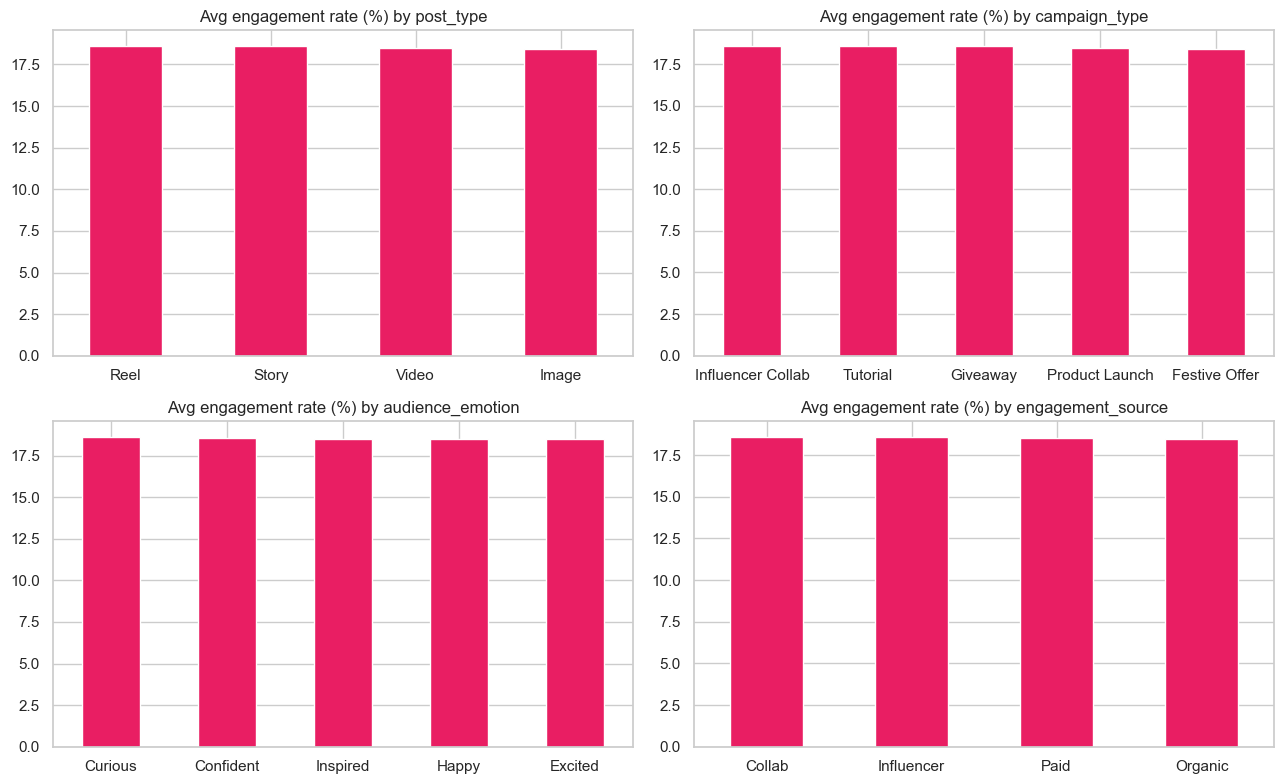

In [32]:
def summarise(col):
    return (df.groupby(col).agg(posts=("post_id", "count"), avg_reach=("reach", "mean"),
            avg_interactions=("interactions", "mean"), avg_eng_rate=("engagement_rate_reach", "mean"),
            avg_follows=("follows", "mean"), follow_conv=("follow_conversion", "mean"))
            .round(2).sort_values("avg_eng_rate", ascending=False))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), CATEGORY_COLS):
    t = summarise(col); display(t)
    t["avg_eng_rate"].plot.bar(ax=ax, color="#e91e63", title=f"Avg engagement rate (%) by {col}", rot=0)
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

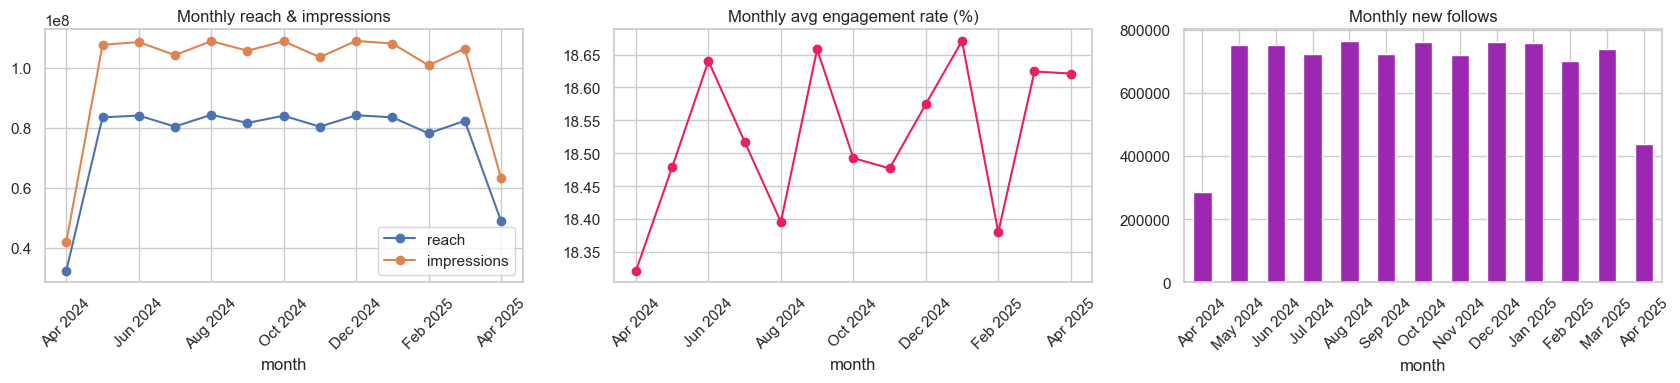

In [33]:
monthly = df.groupby("month").agg(posts=("post_id", "count"), reach=("reach", "sum"),
                                  impressions=("impressions", "sum"),
                                  eng_rate=("engagement_rate_reach", "mean"),
                                  follows=("follows", "sum"))
monthly.index = monthly.index.strftime("%b %Y")
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
monthly[["reach", "impressions"]].plot(ax=ax[0], marker="o", title="Monthly reach & impressions", rot=45)
monthly["eng_rate"].plot(ax=ax[1], marker="o", color="#e91e63", title="Monthly avg engagement rate (%)", rot=45)
monthly["follows"].plot.bar(ax=ax[2], color="#9c27b0", title="Monthly new follows", rot=45)
plt.tight_layout(); plt.show()

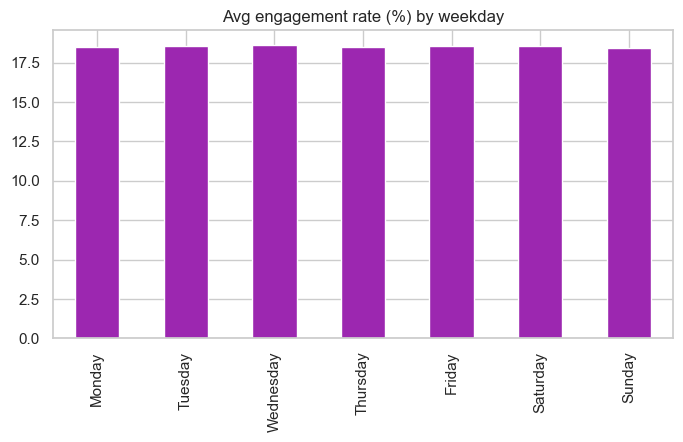

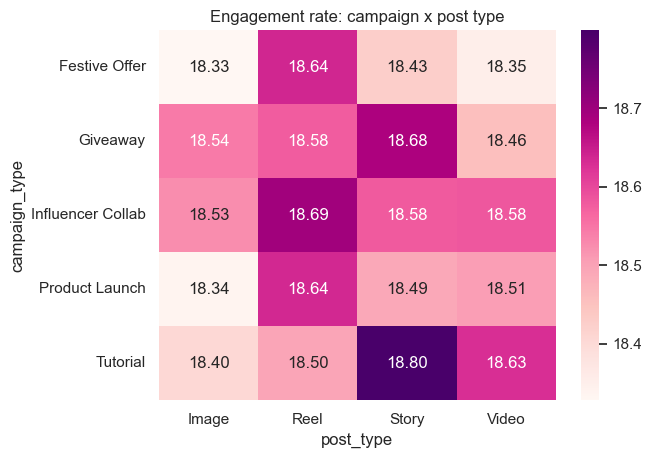

In [34]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df.groupby("weekday")["engagement_rate_reach"].mean().reindex(order).plot.bar(
    color="#9c27b0", figsize=(8, 4), title="Avg engagement rate (%) by weekday")
plt.xlabel(""); plt.show()

heat = df.pivot_table(index="campaign_type", columns="post_type", values="engagement_rate_reach", aggfunc="mean")
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdPu"); plt.title("Engagement rate: campaign x post type"); plt.show()

,uses,avg_reach,avg_eng
hashtag,,,
#veganbeauty,19982,19781.62,18.61
#boldlooks,19956,19855.77,18.58
#crueltyfree,20197,19855.60,18.54
#sugarcosmetics,19891,19735.52,18.52
#makeupgoals,20018,19810.06,18.51


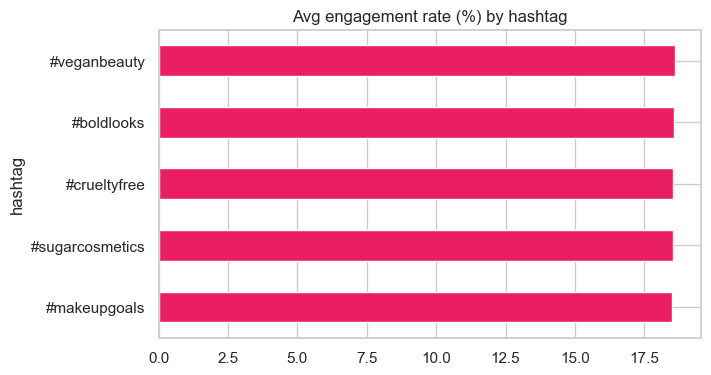

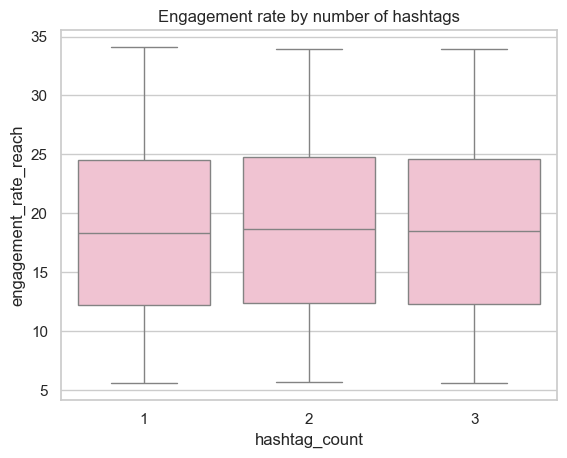

In [35]:
top_tags = (hashtags.groupby("hashtag").agg(uses=("post_id", "count"),
            avg_reach=("reach", "mean"), avg_eng=("engagement_rate_reach", "mean"))
            .round(2).sort_values("avg_eng", ascending=False))
display(top_tags)
top_tags["avg_eng"].sort_values().plot.barh(figsize=(7, 4), color="#e91e63", title="Avg engagement rate (%) by hashtag")
plt.show()

sns.boxplot(data=df, x="hashtag_count", y="engagement_rate_reach", color="#f8bbd0")
plt.title("Engagement rate by number of hashtags"); plt.show()

,total
Impressions,1276045750
Reach,987423288
Interactions,183164417
Profile visits,29634798
Follows,8866710


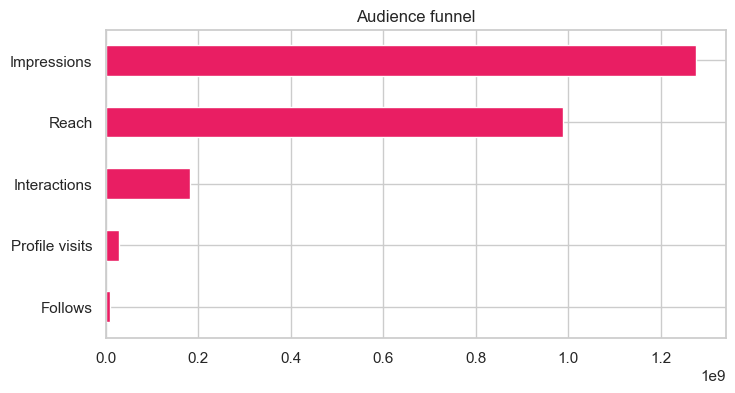

In [36]:
# Funnel: impressions -> reach -> interactions -> profile visits -> follows
funnel = pd.Series({"Impressions": df["impressions"].sum(), "Reach": df["reach"].sum(),
                    "Interactions": df["interactions"].sum(),
                    "Profile visits": df["profile_visits"].sum(), "Follows": df["follows"].sum()})
display(funnel.to_frame("total"))
funnel.iloc[::-1].plot.barh(figsize=(8, 4), color="#e91e63", title="Audience funnel"); plt.show()

In [37]:
cols = ["post_id", "post_date", "post_type", "campaign_type", "reach", "interactions", "engagement_rate_reach", "follows"]
print("Top 10 posts by engagement rate"); display(df.nlargest(10, "engagement_rate_reach")[cols])
print("Bottom 10 posts by engagement rate"); display(df.nsmallest(10, "engagement_rate_reach")[cols])

Top 10 posts by engagement rate


,post_id,post_date,post_type,campaign_type,reach,interactions,engagement_rate_reach,follows
48171,48172,2025-04-05,Image,Influencer Collab,12710,4334,34.099,75
23695,23696,2024-10-08,Reel,Giveaway,38468,13083,34.010,389
4359,4360,2024-05-21,Story,Giveaway,16322,5551,34.009,59
45087,45088,2025-03-13,Story,Giveaway,27896,9480,33.983,146
25232,25233,2024-10-20,Video,Product Launch,7181,2439,33.965,104
28436,28437,2024-11-13,Image,Influencer Collab,25469,8630,33.884,144
40546,40547,2025-02-08,Reel,Tutorial,35746,12110,33.878,472
36696,36697,2025-01-11,Video,Festive Offer,10304,3490,33.870,95
40483,40484,2025-02-08,Video,Tutorial,21502,7281,33.862,139
28740,28741,2024-11-15,Video,Product Launch,44299,14980,33.816,101


Bottom 10 posts by engagement rate


,post_id,post_date,post_type,campaign_type,reach,interactions,engagement_rate_reach,follows
22493,22494,2024-09-30,Reel,Giveaway,26318,1472,5.593,174
9689,9690,2024-06-28,Video,Tutorial,1750,98,5.600,9
3630,3631,2024-05-15,Reel,Influencer Collab,17745,996,5.613,160
12145,12146,2024-07-16,Image,Tutorial,38225,2157,5.643,791
18483,18484,2024-09-01,Video,Giveaway,26052,1470,5.643,129
49526,49527,2025-04-15,Story,Influencer Collab,3335,189,5.667,27
26282,26283,2024-10-27,Story,Festive Offer,2362,134,5.673,11
18574,18575,2024-09-01,Video,Giveaway,21562,1225,5.681,139
8773,8774,2024-06-21,Video,Festive Offer,27288,1556,5.702,136
41329,41330,2025-02-14,Image,Tutorial,22990,1312,5.707,319


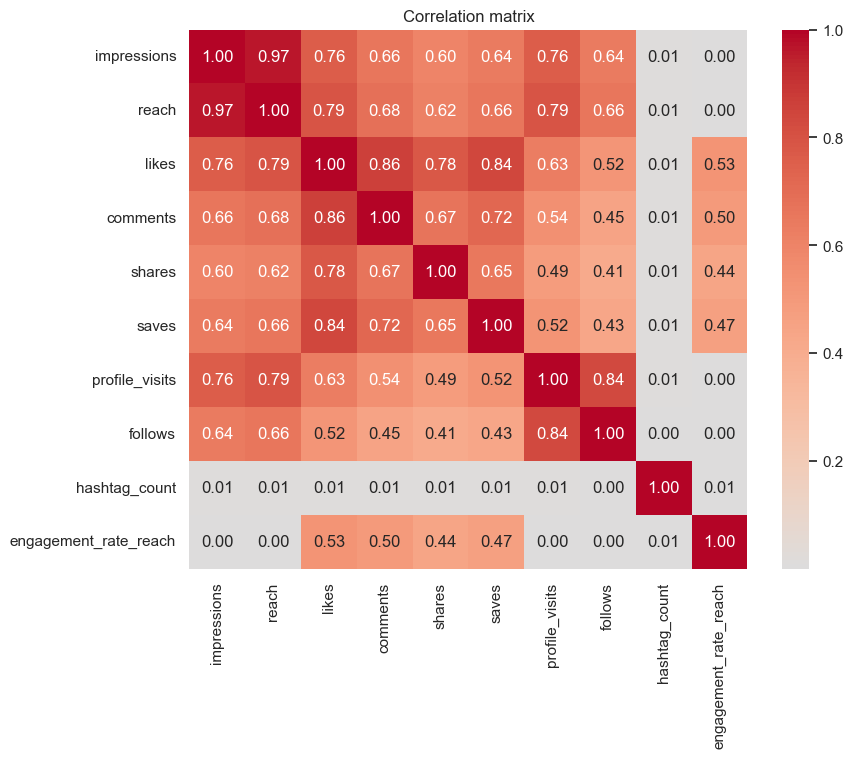

In [38]:
num = ["impressions", "reach", "likes", "comments", "shares", "saves", "profile_visits", "follows", "hashtag_count", "engagement_rate_reach"]
plt.figure(figsize=(9, 7)); sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()